In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
Mounted at /content/drive


In [2]:
!pip install -r requirements.txt
!pip install ultralytics supervision

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/35.0 MB ? eta -:--:--Requirement already satisfied: nvidia-cublas==13.1.0.3.* in /usr/local/lib/python3.13/dist-packages (from cuda-toolkit[cublas,cudart,cufft,cufile,cupti,curand,cusolver,cusparse,nvjitlink,nvrtc,nvtx]==13.0.2; platform_system == "Linux"->torch>=1.8.0->ultralytics) (13.1.0.3)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 178.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 178.3 MB/s  0:00:00
   ━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [av]Installing collected packages: pydeprecate, av, ultralytics-platform, supervision, ultralytics-thop, ultralyt

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/carParking"
os.makedirs(PROJECT_DIR, exist_ok=True)

%cd {PROJECT_DIR}

os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)
os.makedirs("out", exist_ok=True)

/content/drive/MyDrive/carParking


In [5]:
  import cv2
  import json
  import numpy as np
  from ultralytics import YOLO

  VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking3.mp4"

  cap_init = cv2.VideoCapture(VIDEO_PATH)
  ret_init, first_frame = cap_init.read()
  cap_init.release()

  if not ret_init:
      raise Exception(f"Không đọc được video từ đường dẫn: {VIDEO_PATH}")

  orig_h, orig_w = first_frame.shape[:2]
  print(f"✓ Kích thước video gốc: {orig_w} x {orig_h}")

  OUTPUT_PNG_PATH = "first_frame.png"
  cv2.imwrite(OUTPUT_PNG_PATH, first_frame)
  print(f"✓ Đã lưu file PNG đúng chuẩn kích thước video tại: {OUTPUT_PNG_PATH}\n")

✓ Kích thước video gốc: 1190 x 720
✓ Đã lưu file PNG đúng chuẩn kích thước video tại: first_frame.png



In [6]:
import json

JSON_PATH = "/content/drive/MyDrive/carParking/roboflow_output3.json"

with open(JSON_PATH, "r") as f:
    roboflow_data = json.load(f)

preds = roboflow_data.get("predictions", roboflow_data) if isinstance(roboflow_data, dict) else roboflow_data

slots = []
for idx, pred in enumerate(preds, start=1):
    cx = pred["x"]
    cy = pred["y"]
    w = pred["width"]
    h = pred["height"]

    x1 = int(cx - w / 2)
    y1 = int(cy - h / 2)
    x2 = int(cx + w / 2)
    y2 = int(cy + h / 2)

    coords = [
        [x1, y1],
        [x2, y1],
        [x2, y2],
        [x1, y2]
    ]

    slots.append({
        "id": idx,
        "coordinates": coords
    })

with open("slots.json", "w") as f:
    json.dump(slots, f, indent=2)

print(f"✅ Đã chuyển đổi thành công {len(slots)} ô đỗ sang file slots.json!")

✅ Đã chuyển đổi thành công 143 ô đỗ sang file slots.json!


# CHECK Ô BOUBNDING BOX


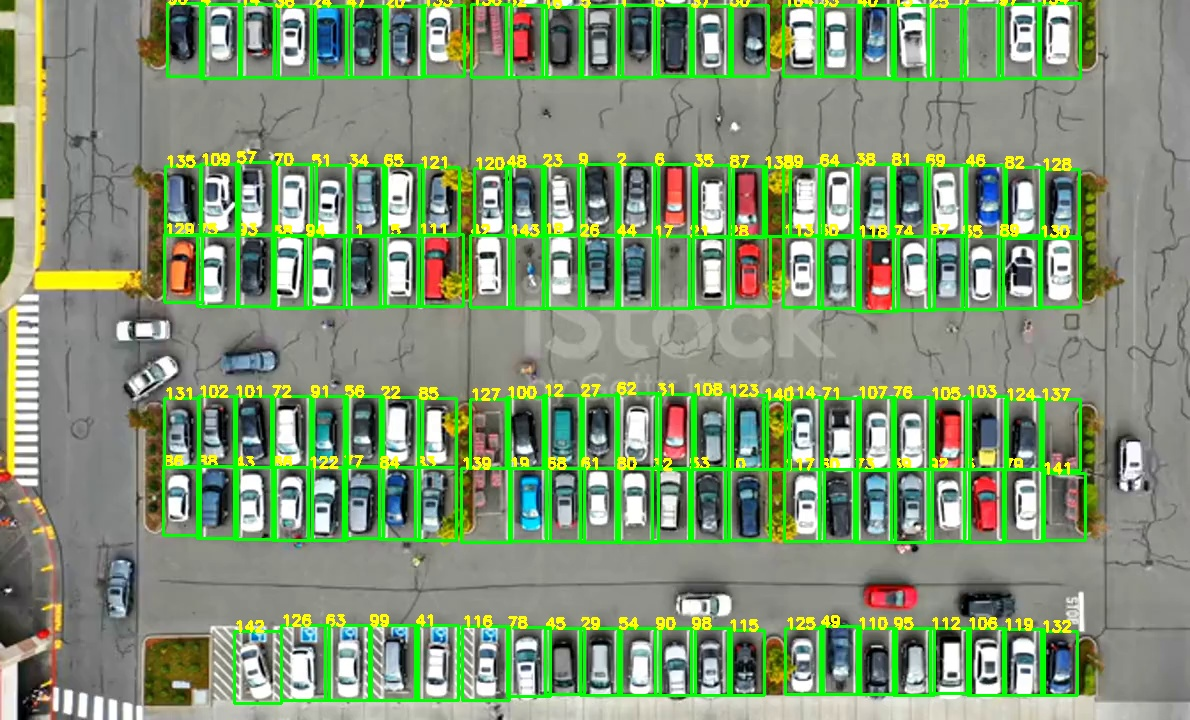

In [9]:
import cv2, json, base64
import IPython.display as display

VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking3.mp4"
SLOTS_PATH = "/content/slots.json"

cap = cv2.VideoCapture(VIDEO_PATH)
ok, frame = cap.read()
cap.release()

if not ok:
    raise ValueError(f"Không thể đọc video tại {VIDEO_PATH}")

with open(SLOTS_PATH, "r") as f:
    slots = json.load(f)

import numpy as np

img_check = frame.copy()
for s in slots:
    pts = np.array(s["coordinates"], np.int32)
    cv2.polylines(img_check, [pts], True, (0, 255, 0), 2)
    cv2.putText(img_check, str(s["id"]), tuple(pts[0]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)

_, buffer = cv2.imencode('.jpg', img_check)
img_b64 = base64.b64encode(buffer).decode('utf-8')

html_code = f"""
<h3>Hình ảnh kiểm tra vị trí các ô đỗ (Tổng số: {len(slots)} ô)</h3>
<img src="data:image/jpeg;base64,{img_b64}" style="max-width: 100%; border: 2px solid #333;" />
"""
display.display(display.HTML(html_code))

# XÓA Ô BOUNDING BOX

In [16]:
import json

SLOTS_PATH = "/content/drive/MyDrive/carParking/slots3.json"

REMOVE_IDS = [127, 139]

with open(SLOTS_PATH, "r") as f:
    slots = json.load(f)

print(f"Tổng số ô ban đầu: {len(slots)}")

filtered_slots = [s for s in slots if s["id"] not in REMOVE_IDS]

for idx, s in enumerate(filtered_slots, start=1):
    s["id"] = idx

with open(SLOTS_PATH, "w") as f:
    json.dump(filtered_slots, f, indent=2)

print(f"✅ Đã xóa {len(slots) - len(filtered_slots)} ô đỗ có ID: {REMOVE_IDS}")
print(f"✅ Số ô đỗ còn lại: {len(filtered_slots)} (đã đánh lại ID liên tục)")

Tổng số ô ban đầu: 143
✅ Đã xóa 2 ô đỗ có ID: [127, 139]
✅ Số ô đỗ còn lại: 141 (đã đánh lại ID liên tục)


# VẼ THÊM BOUNDING BOX

Kích thước video: 1190 x 720
Đã nạp thành công 141 ô đỗ hiện có từ /content/drive/MyDrive/carParking/slots3.json



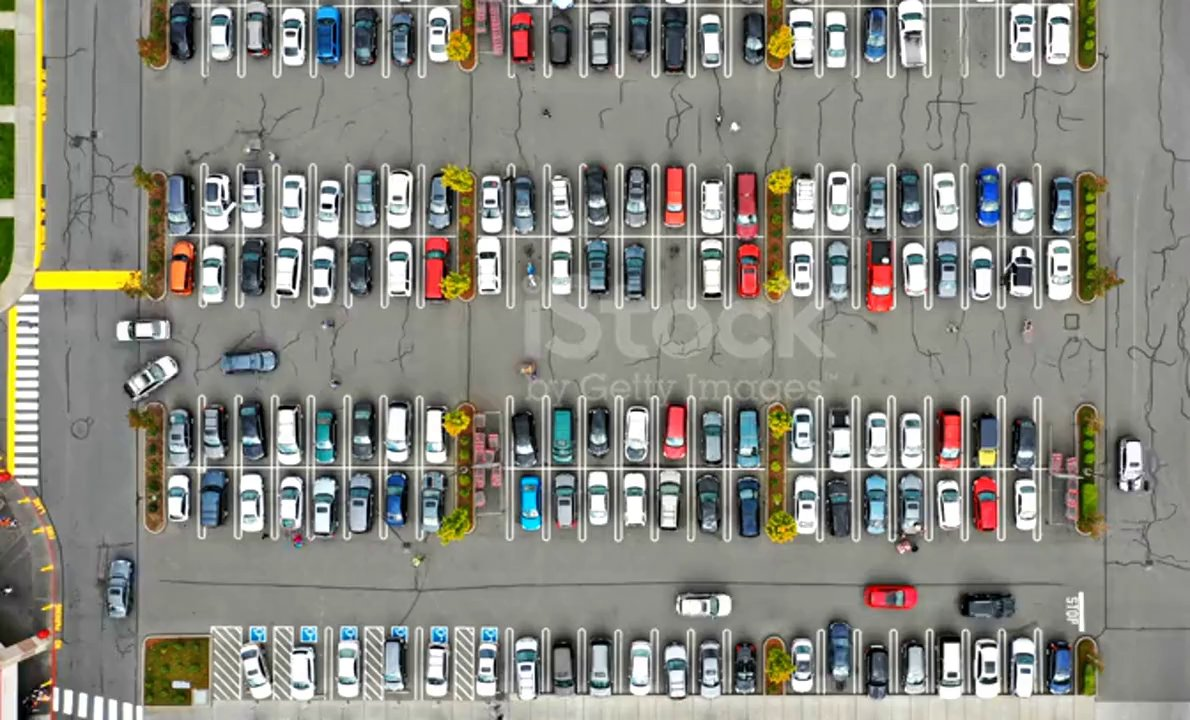


✓ ĐÃ CẬP NHẬT FILE SLOTS.JSON
Tổng số ô đỗ: 141
Đường dẫn file: /content/drive/MyDrive/carParking/slots3.json


In [18]:
import cv2
import json
import base64
import os
from google.colab import output
from IPython.display import display, HTML
from PIL import Image
import io

VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking3.mp4"   # Thay đường dẫn video thật của bạn
SLOT_FILE = "/content/drive/MyDrive/carParking/slots3.json"              # File slots hiện tại cần nạp & bổ sung

cap = cv2.VideoCapture(VIDEO_PATH)
ret, frame = cap.read()
cap.release()

if not ret:
    raise Exception(f"Không đọc được video từ {VIDEO_PATH}")

original_height, original_width = frame.shape[:2]
print(f"Kích thước video: {original_width} x {original_height}")

existing_slots = []
if os.path.exists(SLOT_FILE):
    try:
        with open(SLOT_FILE, "r", encoding="utf-8") as f:
            existing_slots = json.load(f)
        print(f"Đã nạp thành công {len(existing_slots)} ô đỗ hiện có từ {SLOT_FILE}")
    except Exception as e:
        print(f"Lỗi đọc file slots cũ: {e}")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
image = Image.fromarray(frame_rgb)

MAX_WIDTH = 1200
display_width = min(original_width, MAX_WIDTH)
display_height = int(original_height * display_width / original_width)
image_display = image.resize((display_width, display_height))

buffer = io.BytesIO()
image_display.save(buffer, format="JPEG", quality=85)
image_base64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = f"""
<div style="font-family: Arial;">

<h3>🅿️ ĐÁNH DẤU BỔ SUNG CÁC Ô ĐỖ XE CÒN THIẾU</h3>

<p>
<b>Hướng dẫn:</b> Các ô màu xanh lá đã có sẵn từ file. Để vẽ ô mới, click <b>góc thứ nhất</b> ➔ click <b>góc đối diện</b>.
</p>

<div style="margin-bottom:10px;">
<button onclick="undoLast()" style="padding:8px 15px; margin-right:5px; cursor:pointer;">
↩️ Xóa ô vừa vẽ
</button>

<button onclick="finishSlots()" style="padding:8px 15px; background-color:#28a745; color:white; border:none; border-radius:4px; cursor:pointer;">
✅ LƯU ĐÈ VÀO SLOTS.JSON
</button>
</div>

<div style="border:2px solid #333; display:inline-block; position:relative;">
<canvas id="parkingCanvas" width="{display_width}" height="{display_height}" style="cursor:crosshair;">
</canvas>
</div>

<p id="status">
Tổng số ô hiện tại: <b>{len(existing_slots)}</b> ô
</p>

<script>
const canvas = document.getElementById("parkingCanvas");
const ctx = canvas.getContext("2d");
const img = new Image();

const originalWidth = {original_width};
const originalHeight = {original_height};

const scaleX = originalWidth / canvas.width;
const scaleY = originalHeight / canvas.height;

// Nạp danh sách ô đã có sẵn từ Python
let slots = {json.dumps(existing_slots)};
let initialCount = slots.length;
let currentPoints = [];

img.onload = function() {{
    redraw();
}};

img.src = "data:image/jpeg;base64,{image_base64}";

canvas.addEventListener("click", function(event) {{
    const rect = canvas.getBoundingClientRect();
    const x = event.clientX - rect.left;
    const y = event.clientY - rect.top;

    currentPoints.push({{ x: x, y: y }});

    // Vẽ chấm tròn điểm click
    ctx.fillStyle = "yellow";
    ctx.beginPath();
    ctx.arc(x, y, 4, 0, 2 * Math.PI);
    ctx.fill();

    // Đủ 2 điểm góc ➔ Tạo ô đỗ mới
    if (currentPoints.length === 2) {{
        const p1 = currentPoints[0];
        const p2 = currentPoints[1];

        const x1 = Math.round(Math.min(p1.x, p2.x) * scaleX);
        const y1 = Math.round(Math.min(p1.y, p2.y) * scaleY);
        const x2 = Math.round(Math.max(p1.x, p2.x) * scaleX);
        const y2 = Math.round(Math.max(p1.y, p2.y) * scaleY);

        const newId = slots.length + 1;

        // Lưu dạng Polygon 4 góc tương thích với pipeline code
        slots.push({{
            "id": newId,
            "coordinates": [
                [x1, y1],
                [x2, y1],
                [x2, y2],
                [x1, y2]
            ]
        }});

        currentPoints = [];
        redraw();
    }}
}});

function redraw() {{
    ctx.drawImage(img, 0, 0, canvas.width, canvas.height);

    for (let i = 0; i < slots.length; i++) {{
        const s = slots[i];
        let x1, y1, x2, y2;

        // Xử lý tọa độ từ coordinates
        if (s.coordinates && s.coordinates.length >= 4) {{
            x1 = s.coordinates[0][0] / scaleX;
            y1 = s.coordinates[0][1] / scaleY;
            x2 = s.coordinates[2][0] / scaleX;
            y2 = s.coordinates[2][1] / scaleY;
        }} else {{
            continue;
        }}

        // Phân biệt ô cũ và ô vừa vẽ thêm bằng màu sắc
        if (i < initialCount) {{
            ctx.strokeStyle = "#00FF00"; // Màu xanh lá cho ô cũ
        }} else {{
            ctx.strokeStyle = "#FFD700"; // Màu vàng cho ô mới vẽ
        }}

        ctx.lineWidth = 2;
        ctx.strokeRect(x1, y1, x2 - x1, y2 - y1);

        // Hiển thị ID ô
        ctx.fillStyle = "yellow";
        ctx.font = "bold 16px Arial";
        ctx.fillText(s.id, x1 + 4, y1 + 18);
    }}

    document.getElementById("status").innerHTML =
        "Tổng số ô: <b>" + slots.length + "</b> (Cũ: " + initialCount + " | Mới vẽ: " + (slots.length - initialCount) + ")";
}}

function undoLast() {{
    if (slots.length <= initialCount) {{
        alert("Không thể xóa các ô cũ đã nạp sẵn!");
        return;
    }}
    slots.pop();
    currentPoints = [];
    redraw();
}}

async function finishSlots() {{
    google.colab.kernel.invokeFunction(
        'notebook.saveSlots',
        [JSON.stringify(slots, null, 2)],
        {{}}
    );

    document.getElementById("status").innerHTML =
        "✅ ĐÃ LƯU THÀNH CÔNG " + slots.length + " Ô VÀO SLOTS.JSON!";
}}
</script>
</div>
"""

# ============================================
# HÀM LƯU FILE VÀO SLOTS.JSON
# ============================================
def save_slots_from_js(slots_json):
    parking_slots = json.loads(slots_json)

    # Cập nhật đánh lại ID theo thứ tự 1..N
    for idx, s in enumerate(parking_slots, start=1):
        s["id"] = idx

    with open(SLOT_FILE, "w", encoding="utf-8") as f:
        json.dump(parking_slots, f, indent=2, ensure_ascii=False)

    print("\n================================")
    print("✓ ĐÃ CẬP NHẬT FILE SLOTS.JSON")
    print("================================")
    print("Tổng số ô đỗ:", len(parking_slots))
    print("Đường dẫn file:", SLOT_FILE)

output.register_callback("notebook.saveSlots", save_slots_from_js)
display(HTML(html))

# Kiểm tra lưới ô đỗ

In [ ]:
%%writefile overlay_slots.py
import argparse
import json
import cv2
import numpy as np

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--slots", required=True)
    ap.add_argument("--frames", type=int, nargs="*", default=[0, 300])
    ap.add_argument("--save", default="overlay_slots.png")
    args = ap.parse_args()

    slots = json.load(open(args.slots, encoding="utf-8"))
    cap = cv2.VideoCapture(args.video)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    xs = [p[0] for s in slots for p in s["coordinates"]]
    ys = [p[1] for s in slots for p in s["coordinates"]]
    print(f"Video: {W}x{H}, {n} frame | {len(slots)} ô | Tọa độ x: {min(xs)}..{max(xs)}, y: {min(ys)}..{max(ys)}")

    if max(xs) > W or max(ys) > H:
        print("⚠️ CẢNH BÁO: Tọa độ ô nằm ngoài khung hình -> slots.json vẽ cho video khác resolution!")

    panels = []
    for f in args.frames:
        f = min(max(f, 0), n - 1)
        cap.set(cv2.CAP_PROP_POS_FRAMES, f)
        ok, im = cap.read()
        if not ok: continue
        for s in slots:
            cv2.polylines(im, [np.array(s["coordinates"], np.int32)], True, (0, 255, 0), 1, cv2.LINE_AA)
        cv2.putText(im, f"frame {f}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
        panels.append(im)
    cap.release()
    cv2.imwrite(args.save, np.vstack(panels) if len(panels) > 1 else panels[0])
    print(f"✅ Đã lưu hình ảnh kiểm tra tại: {args.save}")

if __name__ == "__main__":
    main()

Overwriting overlay_slots.py


In [ ]:
!python overlay_slots.py \
    --video /content/drive/MyDrive/carParking/data/carParking2.mp4 \
    --slots /content/drive/MyDrive/carParking/slots.json

Video: 3700x2082, 849 frame | 391 ô | Tọa độ x: 127..3565, y: 185..2082
✅ Đã lưu hình ảnh kiểm tra tại: overlay_slots.png


In [ ]:
!pip install lap==0.5.13


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 9.1 MB/s eta 0:00:00


# CHẠY CHƯƠNG TRÌNH


In [ ]:

import sys
import os
import shutil
import subprocess
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/carParking"
IN_COLAB_PROJECT = os.path.exists(PROJECT_PATH)
if IN_COLAB_PROJECT:
    sys.path.append(PROJECT_PATH)
    os.chdir(PROJECT_PATH)

import argparse
import csv
import json
import time
from collections import deque

import cv2
import numpy as np

if IN_COLAB_PROJECT:
    slots_path = "/content/drive/MyDrive/carParking/slots.json"
    if not os.path.exists(slots_path):
        slots_path = os.path.join(PROJECT_PATH, "slots.json")
    sys.argv = [
        "parking_monitor_styled.py",
        "--video", "/content/drive/MyDrive/carParking/data/carParking.mp4",
        "--weights", "/content/drive/MyDrive/carParking/models/best11n.pt",
        "--slots", slots_path,
        "--classes", "0", "car",
        "--imgsz", "1184",
        "--conf", "0.5",
        "--theta", "0.35",
        "--window", "9",
        "--dwell", "15",
        "--scale", "1.0",
        "--out", "out/result_styled.mp4",
        "--log", "out/log.csv",
        # "--groups", "6",        # số cột/nhóm màu
        # "--preview", "out/preview.png",   # chỉ xuất 1 ảnh để kiểm tra giao diện, không chạy model
    ]

GROUP_COLORS = [
    (255, 73, 137),    # tím
    (75, 250, 255),    # vàng
    (99, 44, 255),     # đỏ
    (255, 241, 56),    # cyan
    (249, 60, 255),    # hồng
    (255, 255, 255),   # trắng
]
FREE_COLOR = (51, 255, 49)  # xanh lá


def assign_groups(slots, n_groups):
    """Gom ô thành cột: cắt tại (n_groups - 1) khoảng trống lớn nhất giữa các tâm x.
    Trả về mảng chỉ số nhóm (0 = cột trái nhất) theo thứ tự `slots`."""
    cx = np.array([np.mean([p[0] for p in s["coordinates"]]) for s in slots], dtype=float)
    if n_groups <= 1 or len(cx) <= n_groups:
        return np.zeros(len(cx), dtype=int)
    xs = np.sort(cx)
    gaps = np.diff(xs)
    cut = np.sort(np.argsort(gaps)[-(n_groups - 1):])
    bounds = xs[cut] + gaps[cut] / 2.0
    return np.searchsorted(bounds, cx).astype(int)


def shrink(pts, margin):
    """Co polygon vào phía tâm 1 khoảng cố định -> các ô liền kề không đè viền lên nhau."""
    pts = np.asarray(pts, dtype=float)
    d = pts.mean(axis=0) - pts
    dist = np.linalg.norm(d, axis=1, keepdims=True)
    step = np.minimum(margin, dist * 0.4)
    return pts + d / np.maximum(dist, 1e-9) * step


def load_font(px):
    """Font đậm cho dòng chữ đầu trang; không có thì trả None (dùng cv2.putText)."""
    try:
        from PIL import ImageFont
    except ImportError:
        return None
    cands = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
        "C:/Windows/Fonts/arialbd.ttf",
        "/System/Library/Fonts/Supplemental/Arial Bold.ttf",
        "arialbd.ttf",
        "DejaVuSans-Bold.ttf",
    ]
    try:
        import matplotlib.font_manager as fm
        cands.insert(0, fm.findfont("DejaVu Sans:bold", fallback_to_default=False))
    except Exception:
        pass
    for p in cands:
        try:
            return ImageFont.truetype(p, px)
        except Exception:
            continue
    return None


class Renderer:
    """Vẽ 1 khung hình theo giao diện ảnh mẫu. Khung xuất ra = video (phóng to `scale`)
    + thanh đen cao `bar_h` ở trên."""

    def __init__(self, slots, W, H, scale=2.0, n_groups=6, alpha=0.35, inset=1.0, line=2):
        self.s = float(scale)
        self.W_out = int(W * self.s) // 2 * 2
        self.H_out = int(H * self.s) // 2 * 2
        self.bar_h = int(round(48 * self.s)) // 2 * 2
        self.size = (self.W_out, self.H_out + self.bar_h)   # (width, height) khung xuất ra
        self.alpha, self.line = alpha, max(1, int(line))
        self.ids = [sl["id"] for sl in slots]
        self.idx = {i: k for k, i in enumerate(self.ids)}
        self.gid = assign_groups(slots, n_groups)
        self.n_groups = int(self.gid.max()) + 1 if len(self.gid) else 0
        raw = [np.asarray(sl["coordinates"], dtype=float) * self.s for sl in slots]
        self.polys = [np.round(shrink(p, inset * self.s)).astype(np.int32) for p in raw]
        self.gx = [min(p[:, 0].min() for p, g in zip(raw, self.gid) if g == k)
                   for k in range(self.n_groups)]                      # x bắt đầu từng cột
        self.font = load_font(int(round(17 * self.s)))
        self._hkey, self._hbar = None, None             # cache thanh chữ đầu trang

    def group_sizes(self):
        return [int((self.gid == k).sum()) for k in range(self.n_groups)]

    def render(self, frame, occupied, vehicles=None):
        """frame: BGR gốc | occupied: mảng bool theo thứ tự slots | vehicles: tuỳ chọn (--show-cars)"""
        canvas = np.zeros((self.size[1], self.size[0], 3), dtype=np.uint8)
        vis = frame
        if (self.W_out, self.H_out) != (frame.shape[1], frame.shape[0]):
            vis = cv2.resize(frame, (self.W_out, self.H_out), interpolation=cv2.INTER_CUBIC)
        canvas[self.bar_h:] = vis
        roi = canvas[self.bar_h:]                                       # view, vẽ trực tiếp

        occ = np.asarray(occupied, dtype=bool)
        free_idx = np.nonzero(~occ)[0]
        if len(free_idx):
            free_polys = [self.polys[i] for i in free_idx]
            overlay = roi.copy()
            cv2.fillPoly(overlay, free_polys, FREE_COLOR)
            cv2.addWeighted(overlay, self.alpha, roi, 1.0 - self.alpha, 0, roi)
            cv2.polylines(roi, free_polys, True, FREE_COLOR, self.line, cv2.LINE_AA)
        for g in range(self.n_groups):
            ps = [self.polys[i] for i in np.nonzero(occ & (self.gid == g))[0]]
            if ps:
                cv2.polylines(roi, ps, True, GROUP_COLORS[g % len(GROUP_COLORS)], self.line, cv2.LINE_AA)

        if vehicles:
            for v in vehicles:
                x1, y1, x2, y2 = (int(c * self.s) for c in v["box"])
                cv2.rectangle(roi, (x1, y1), (x2, y2), (255, 200, 0), 1, cv2.LINE_AA)

        counts = [(int((occ & (self.gid == g)).sum()), int(((~occ) & (self.gid == g)).sum()))
                  for g in range(self.n_groups)]
        if tuple(counts) != self._hkey:                  # chỉ vẽ lại chữ khi số đếm đổi
            bar = np.zeros((self.bar_h, self.W_out, 3), dtype=np.uint8)
            self._header(bar, counts)
            self._hkey, self._hbar = tuple(counts), bar
        canvas[:self.bar_h] = self._hbar
        return canvas

    def _header(self, bar, counts):
        if self.font is not None:
            from PIL import Image, ImageDraw
            img = Image.fromarray(bar[:, :, ::-1].copy())              # BGR -> RGB
            d = ImageDraw.Draw(img)
            for g, (n_occ, n_free) in enumerate(counts):
                t1, t2 = f"{n_occ} occupied", f"{n_free} free"
                w = max(d.textlength(t1, font=self.font), d.textlength(t2, font=self.font))
                x = int(max(4 * self.s, min(self.gx[g], self.W_out - w - 8 * self.s)))
                d.text((x, int(0.04 * self.bar_h)), t1, font=self.font,
                       fill=GROUP_COLORS[g % len(GROUP_COLORS)][::-1])
                d.text((x, int(0.50 * self.bar_h)), t2, font=self.font, fill=FREE_COLOR[::-1])
            bar[:] = np.array(img)[:, :, ::-1]
        else:                                                           # dự phòng: font Hershey
            for g, (n_occ, n_free) in enumerate(counts):
                x = int(max(4 * self.s, self.gx[g]))
                th = max(1, int(round(1.5 * self.s)))
                cv2.putText(bar, f"{n_occ} occupied", (x, int(0.42 * self.bar_h)), cv2.FONT_HERSHEY_DUPLEX,
                            0.62 * self.s, GROUP_COLORS[g % len(GROUP_COLORS)], th, cv2.LINE_AA)
                cv2.putText(bar, f"{n_free} free", (x, int(0.88 * self.bar_h)), cv2.FONT_HERSHEY_DUPLEX,
                            0.62 * self.s, FREE_COLOR, th, cv2.LINE_AA)



BG, PANEL, BORDER = (11, 14, 19), (21, 26, 34), (35, 43, 54)        # RGB
TXT, SOFT, MUTED = (230, 234, 240), (197, 204, 216), (139, 149, 165)
OKC = (61, 220, 132)
_FONTS = {}


def ttf(size, bold=False):
    """Font TrueType (DejaVu: có đủ tiếng Việt). Không thấy font -> font mặc định của PIL."""
    from PIL import ImageFont
    key = (int(size), bool(bold))
    if key in _FONTS:
        return _FONTS[key]
    nm = "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"
    cands = [f"/usr/share/fonts/truetype/dejavu/{nm}", nm,
             "C:/Windows/Fonts/arialbd.ttf" if bold else "C:/Windows/Fonts/arial.ttf",
             "/System/Library/Fonts/Supplemental/Arial Bold.ttf" if bold else "/System/Library/Fonts/Supplemental/Arial.ttf"]
    try:
        import matplotlib.font_manager as fm
        cands.insert(0, fm.findfont("DejaVu Sans:bold" if bold else "DejaVu Sans", fallback_to_default=False))
    except Exception:
        pass
    f = None
    for p in cands:
        try:
            f = ImageFont.truetype(p, int(size))
            break
        except Exception:
            continue
    if f is None:
        try:
            f = ImageFont.load_default(int(size))
        except TypeError:
            f = ImageFont.load_default()
    _FONTS[key] = f
    return f


def _rgb(bgr):
    return tuple(int(c) for c in bgr[::-1])


class Dashboard:
    SIZE = (1920, 1080)

    def __init__(self, slots_raw, W, H, fps, args):
        from PIL import Image, ImageDraw
        self.fps, self.warmup = float(fps), int(args.warmup)
        self.left = (32, 236, 1268, 1048)                               # khung video
        inner_w = (self.left[2] - self.left[0]) - 40
        inner_h = (self.left[3] - self.left[1]) - 56 - 20
        s = min(inner_w / W, inner_h / (H + 48))
        self.rd = Renderer(slots_raw, W, H, s, args.groups, args.alpha, args.inset, args.line)
        vw, vh = self.rd.size
        self.vx = self.left[0] + (self.left[2] - self.left[0] - vw) // 2
        self.vy = self.left[1] + 56
        self.n, self.ng = len(slots_raw), self.rd.n_groups
        self.ids, self.gid = self.rd.ids, self.rd.gid
        self.sizes = np.array(self.rd.group_sizes())
        self.names = [f"Khu {chr(65 + g)}" if g < 26 else f"Khu {g + 1}" for g in range(self.ng)]
        self.events, self.hist, self.prev = deque(maxlen=5), [], None
        self.sample_every, self.window = max(1, int(round(self.fps / 4))), 120
        m = Image.new("L", (vw, vh), 0)
        ImageDraw.Draw(m).rounded_rectangle([0, 0, vw - 1, vh - 1], radius=10, fill=255)
        self.vmask3 = (np.asarray(m) > 0)[:, :, None]
        self.cw = (1856 - 60) // 4
        self.kx = [32 + i * (self.cw + 20) for i in range(4)]
        self.zpitch = min(44, 264 // max(1, self.ng))
        self.chart = (1344, 1864, 888, 1018)
        self.base_np = np.asarray(self._static())      # RGB, dựng 1 lần

    def _static(self):
        from PIL import Image, ImageDraw
        k = 2
        img = Image.new("RGB", (self.SIZE[0] * k, self.SIZE[1] * k), BG)
        d = ImageDraw.Draw(img)

        def rr(x1, y1, x2, y2, fill=PANEL, outline=BORDER, r=14):
            d.rounded_rectangle([x1 * k, y1 * k, x2 * k, y2 * k], radius=r * k, fill=fill, outline=outline, width=k)

        def tx(x, y, t, size, color=TXT, bold=False, anchor="la"):
            d.text((x * k, y * k), t, font=ttf(size * k, bold), fill=color, anchor=anchor)

        d.line([0, 80 * k, self.SIZE[0] * k, 80 * k], fill=BORDER, width=k)
        rr(32, 20, 76, 64, fill=TXT, outline=None, r=11)
        tx(54, 42, "P", 28, BG, True, "mm")
        tx(92, 18, "Smart Parking", 26, TXT, True)
        tx(92, 50, "Bãi xe A · camera góc nhìn từ trên", 15, MUTED)
        rr(1628, 26, 1716, 62, fill=(16, 40, 28), outline=(29, 74, 49), r=18)
        d.ellipse([1645 * k, 39 * k, 1655 * k, 49 * k], fill=OKC)
        tx(1666, 44, "LIVE", 15, OKC, True, "lm")
        for x, lab in zip(self.kx, ["Ô còn trống", "Đang có xe", "Khu nhiều chỗ nhất", "Tốc độ xử lý"]):
            rr(x, 96, x + self.cw, 220)
            tx(x + 24, 110, lab, 15, MUTED)
        L = self.left
        rr(*L)
        tx(L[0] + 24, L[1] + 16, "Camera 01 · giám sát thời gian thực", 20, TXT, True)
        rr(1288, 236, 1888, 566); tx(1312, 254, "Theo khu vực", 20, TXT, True)
        rr(1288, 582, 1888, 812); tx(1312, 600, "Hoạt động gần đây", 20, TXT, True)
        rr(1288, 828, 1888, 1048); tx(1312, 846, "Công suất bãi xe", 20, TXT, True)
        for g in range(self.ng):
            y = 296 + g * self.zpitch
            d.rounded_rectangle([1312 * k, (y + 8) * k, 1326 * k, (y + 22) * k], radius=3 * k,
                                fill=_rgb(GROUP_COLORS[g % len(GROUP_COLORS)]))
            tx(1336, y + 15, self.names[g], 17, SOFT, False, "lm")
        cx1, cx2, cy1, cy2 = self.chart
        for v in (0, 25, 50, 75, 100):
            y = cy2 - (cy2 - cy1) * v / 100
            d.line([cx1 * k, y * k, cx2 * k, y * k], fill=BORDER, width=k)
            tx(cx1 - 8, y, f"{v}%", 12, MUTED, False, "rm")
        tx(cx1, 1026, "-30 giây", 12, MUTED)
        tx(cx2, 1026, "bây giờ", 12, MUTED, False, "ra")
        return img.resize(self.SIZE, Image.LANCZOS)

    def demo_fill(self):
        """Dữ liệu minh hoạ cho --preview (không dùng khi chạy thật)."""
        self.hist = [58 + 7 * np.sin(i / 9.0) + i * 0.08 for i in range(120)]
        for j, (sid, g, st) in enumerate([(118, 0, True), (196, min(4, self.ng - 1), True), (193, min(3, self.ng - 1), False)]):
            self.events.append((12.0 + 8 * j, sid, self.names[g], st, g))

    def render(self, frame, occ, vehicles, frame_idx, fps_now):
        """Trả về khung RGB 1920x1080 (HQWriter nhận in_pix='rgb24')."""
        from PIL import Image, ImageDraw
        occ = np.asarray(occ, dtype=bool)
        t = frame_idx / self.fps
        if self.prev is not None and frame_idx >= self.warmup:
            for i in np.nonzero(occ != self.prev)[0]:
                self.events.appendleft((t, self.ids[i], self.names[self.gid[i]], bool(occ[i]), int(self.gid[i])))
        self.prev = occ.copy()
        # Không ghi lịch sử trong lúc engine khởi động (các frame đầu mọi ô còn 'trống' giả tạo)
        if frame_idx >= self.warmup and frame_idx % self.sample_every == 0:
            self.hist.append(100.0 * occ.mean())

        canvas = self.base_np.copy()                                     # RGB
        vid = self.rd.render(frame, occ, vehicles)                       # BGR
        vh, vw = vid.shape[:2]
        np.copyto(canvas[self.vy:self.vy + vh, self.vx:self.vx + vw], vid[:, :, ::-1], where=self.vmask3)

        # biểu đồ công suất (OpenCV trên canvas RGB)
        cx1, cx2, cy1, cy2 = self.chart
        h = self.hist[-self.window:]
        if len(h) >= 2:
            pts = np.array([(cx1 + i * (cx2 - cx1) / (self.window - 1), cy2 - (cy2 - cy1) * v / 100)
                            for i, v in enumerate(h)])
            poly = np.round(np.vstack([[pts[0, 0], cy2], pts, [pts[-1, 0], cy2]])).astype(np.int32)
            roi = canvas[cy1 - 4:cy2 + 4, cx1 - 4:cx2 + 4]
            ov = roi.copy()
            cv2.fillPoly(ov, [poly - np.array([cx1 - 4, cy1 - 4], dtype=np.int32)], OKC)
            cv2.addWeighted(ov, 0.14, roi, 0.86, 0, roi)
            cv2.polylines(canvas, [np.round(pts).astype(np.int32)], False, OKC, 3, cv2.LINE_AA)
            cv2.circle(canvas, (int(round(pts[-1, 0])), int(round(pts[-1, 1]))), 5, OKC, -1, cv2.LINE_AA)

        img = Image.fromarray(canvas)
        d = ImageDraw.Draw(img)

        def tx(x, y, s, size, color=TXT, bold=False, anchor="la"):
            d.text((x, y), s, font=ttf(size, bold), fill=color, anchor=anchor)

        mm = lambda sec: f"{int(sec // 60):02d}:{int(sec % 60):02d}"
        n_occ = int(occ.sum()); n_free = self.n - n_occ
        occ_g = np.array([int((occ & (self.gid == g)).sum()) for g in range(self.ng)])
        free_g = self.sizes - occ_g
        pct = 100.0 * n_occ / max(1, self.n)

        tx(1888, 44, mm(t), 17, SOFT, False, "rm")
        y0 = 96
        x = self.kx[0]
        tx(x + 24, y0 + 34, f"{n_free}", 48, OKC, True)
        tx(x + 24 + d.textlength(f"{n_free}", font=ttf(48, True)) + 8, y0 + 62, f"/ {self.n}", 20, MUTED)
        tx(x + 24, y0 + 96, f"{100 * n_free / max(1, self.n):.0f}% tổng số ô", 14, MUTED)
        x = self.kx[1]
        tx(x + 24, y0 + 34, f"{n_occ}", 48, TXT, True)
        tx(x + 24, y0 + 96, f"Công suất {pct:.0f}%", 14, MUTED)
        d.rounded_rectangle([x + 24, y0 + 115, x + self.cw - 24, y0 + 119], radius=2, fill=BORDER)
        d.rounded_rectangle([x + 24, y0 + 115, x + 24 + (self.cw - 48) * pct / 100, y0 + 119], radius=2, fill=TXT)
        x = self.kx[2]
        kb = int(np.argmax(free_g)) if self.ng else 0
        tx(x + 24, y0 + 34, self.names[kb], 48, _rgb(GROUP_COLORS[kb % len(GROUP_COLORS)]), True)
        tx(x + 24, y0 + 96, f"{int(free_g[kb])} ô trống", 14, MUTED)
        x = self.kx[3]
        tx(x + 24, y0 + 34, f"{fps_now:.0f}", 48, TXT, True)
        tx(x + 24 + d.textlength(f"{fps_now:.0f}", font=ttf(48, True)) + 8, y0 + 62, "fps", 20, MUTED)
        tx(x + 24, y0 + 96, "YOLO + ByteTrack · đo trên model + engine", 14, MUTED)

        for g in range(self.ng):
            y = 296 + g * self.zpitch
            d.rounded_rectangle([1424, y + 11, 1790, y + 19], radius=4, fill=BORDER)
            wbar = 366 * occ_g[g] / max(1, self.sizes[g])
            if wbar >= 1:
                d.rounded_rectangle([1424, y + 11, 1424 + wbar, y + 19], radius=4, fill=_rgb(GROUP_COLORS[g % len(GROUP_COLORS)]))
            tx(1864, y + 15, f"{occ_g[g]}/{self.sizes[g]}", 16, SOFT, False, "rm")

        if not self.events:
            tx(1312, 640, "Chưa có thay đổi trạng thái", 15, MUTED)
        for i, (te, sid, gname, st, g) in enumerate(self.events):
            y = 640 + i * 34
            col = _rgb(GROUP_COLORS[g % len(GROUP_COLORS)]) if st else OKC
            d.ellipse([1308, y + 5, 1316, y + 13], fill=col)
            tx(1332, y + 9, f"Ô {sid} · {gname} → {'có xe' if st else 'trống'}", 16, SOFT, False, "lm")
            tx(1864, y + 9, mm(te), 13, MUTED, False, "rm")
        tx(1864, 846, f"{pct:.0f}%", 22, OKC, True, "ra")
        return np.asarray(img)


class HQWriter:
    """Ghi video H.264 chất lượng cao qua ffmpeg (yuv420p, phát được trên trình duyệt/Drive).
    Không có ffmpeg thì rơi về cv2.VideoWriter (mp4v). size = (width, height), số chẵn."""

    def __init__(self, path, fps, size, crf=18, preset="medium", in_pix="bgr24"):
        self.size, self.proc, self.cv_writer, self.in_pix = size, None, None, in_pix
        w, h = size
        ffmpeg = shutil.which("ffmpeg")
        if ffmpeg:
            cmd = [ffmpeg, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", in_pix,
                   "-s", f"{w}x{h}", "-r", f"{fps}", "-i", "-", "-an", "-c:v", "libx264",
                   "-preset", preset, "-crf", str(crf), "-pix_fmt", "yuv420p",
                   "-movflags", "+faststart", path]
            self.proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
            self.backend = f"ffmpeg libx264 (crf={crf}, preset={preset})"
        else:
            self.cv_writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
            self.backend = "cv2 mp4v (không thấy ffmpeg)"

    def write(self, frame):
        if self.proc is not None:
            try:
                self.proc.stdin.write(frame.tobytes())
            except BrokenPipeError:
                raise RuntimeError(f"ffmpeg dừng đột ngột -- kiểm tra kích thước khung {self.size}")
        else:
            self.cv_writer.write(frame[:, :, ::-1] if self.in_pix == "rgb24" else frame)

    def release(self):
        if self.proc is not None:
            self.proc.stdin.close()
            self.proc.wait()
        else:
            self.cv_writer.release()


def parse_args():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--weights", default="best.pt")
    ap.add_argument("--slots", default="slots.json")
    ap.add_argument("--classes", nargs="+", default=None)
    ap.add_argument("--imgsz", type=int, default=960)
    ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--tracker", default="bytetrack.yaml")
    ap.add_argument("--theta", type=float, default=0.35)
    ap.add_argument("--window", type=int, default=9)
    ap.add_argument("--dwell", type=int, default=15)
    ap.add_argument("--move-frac", type=float, default=0.15)
    ap.add_argument("--out", default="out/result_styled.mp4")
    ap.add_argument("--log", default="out/log.csv")
    # giao diện
    ap.add_argument("--layout", choices=["dashboard", "video"], default="dashboard",
                    help="dashboard: khung 1920x1080 như bản web | video: chỉ video + overlay")
    ap.add_argument("--warmup", type=int, default=30,
                    help="Bỏ qua sự kiện đổi trạng thái trong N frame đầu (lúc engine đang khởi động)")
    ap.add_argument("--groups", type=int, default=6, help="Số cột/nhóm màu")
    ap.add_argument("--scale", type=float, default=2.0, help="(chỉ --layout video) phóng to khung xuất ra")
    ap.add_argument("--preset", default=None, help="Preset x264 (mặc định: veryfast cho dashboard, medium cho video)")
    ap.add_argument("--crf", type=int, default=18, help="Chất lượng H.264 (nhỏ = nét hơn, file lớn hơn)")
    ap.add_argument("--alpha", type=float, default=0.35, help="Độ đậm màu xanh phủ ô trống")
    ap.add_argument("--inset", type=float, default=1.0, help="Co ô vào trong (px gốc) để viền ô liền kề không đè nhau")
    ap.add_argument("--line", type=int, default=2, help="Độ dày viền ô (px khung xuất ra)")
    ap.add_argument("--show-cars", action="store_true", help="Vẽ thêm box xe (debug)")
    ap.add_argument("--preview", default=None, help="Chỉ xuất 1 ảnh PNG (trạng thái giả lập) để kiểm tra giao diện")
    ap.add_argument("--preview-frame", type=int, default=0)
    return ap.parse_args()


def main():
    args = parse_args()
    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    Path(args.log).parent.mkdir(parents=True, exist_ok=True)

    slots_raw = json.loads(Path(args.slots).read_text(encoding="utf-8"))

    cap = cv2.VideoCapture(args.video)
    if not cap.isOpened():
        raise SystemExit(f"Không thể mở video: {args.video}")
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 25
    ok, first_frame = cap.read()
    if not ok:
        raise SystemExit("Không thể đọc video đầu vào!")
    H, W = first_frame.shape[:2]
    print(f"Độ phân giải video gốc: {W}x{H}")

    if args.layout == "dashboard":
        dash = Dashboard(slots_raw, W, H, fps_in, args)
        rd, out_size = dash.rd, Dashboard.SIZE
    else:
        dash = None
        rd = Renderer(slots_raw, W, H, args.scale, args.groups, args.alpha, args.inset, args.line)
        out_size = rd.size
    print(f"Khung xuất ra: {out_size[0]}x{out_size[1]} ({args.layout}) | {len(slots_raw)} ô chia {rd.n_groups} cột: {rd.group_sizes()}")

    # ---- chế độ xem trước: không cần model ----
    if args.preview:
        cap.set(cv2.CAP_PROP_POS_FRAMES, args.preview_frame)
        ok, fr = cap.read()
        fr = fr if ok else first_frame
        demo = np.array([(i * 7919) % 5 != 0 for i in range(len(slots_raw))])   # ~20% ô trống giả lập
        if dash is not None:
            dash.demo_fill()
            out_img = dash.render(fr, demo, None, 0, 25.0)[:, :, ::-1]
        else:
            out_img = rd.render(fr, demo)
        cv2.imwrite(args.preview, out_img)
        print(f"Đã lưu ảnh xem trước (trạng thái GIẢ LẬP): {args.preview}")
        return
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    from ultralytics import YOLO
    from occupancy import SlotEngine, make_slot

    slots = [make_slot(s["id"], s["coordinates"]) for s in slots_raw]
    engine = SlotEngine(slots, args.theta, args.window, args.dwell, args.move_frac)

    model = YOLO(args.weights)
    wanted = None
    if args.classes:
        wanted = {i for i, n in model.names.items() if n in set(args.classes)}
        if not wanted:
            raise SystemExit(f"Không có class nào khớp {args.classes}. model.names = {model.names}")
    print("Classes:", {i: model.names[i] for i in (wanted if wanted is not None else model.names)})

    writer = HQWriter(args.out, fps_in, out_size, crf=args.crf,
                      preset=args.preset or ("veryfast" if dash is not None else "medium"),
                      in_pix="rgb24" if dash is not None else "bgr24")
    print(f"Xuất video bằng {writer.backend}")
    logf = open(args.log, "w", newline="", encoding="utf-8")
    log = csv.writer(logf)
    log.writerow(["frame", "slot_id", "max_ratio", "raw", "track", "final", "track_id"])

    lat, frame_idx = [], 0
    print(f"Bắt đầu xử lý video ({total_frames} frames)...")
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        res = model.track(frame, persist=True, tracker=args.tracker, imgsz=args.imgsz,
                          conf=args.conf, verbose=False)[0]
        vehicles = []
        b = res.boxes
        if b is not None and b.id is not None:
            for bb, tid, c in zip(b.xyxy.cpu().numpy(), b.id.int().cpu().numpy(), b.cls.int().cpu().numpy()):
                if wanted is None or int(c) in wanted:
                    vehicles.append({"id": int(tid), "box": tuple(map(float, bb))})
        results = engine.update(vehicles)
        lat.append((time.perf_counter() - t0) * 1000)

        occ = np.zeros(len(slots_raw), dtype=bool)
        for r in results:
            occ[rd.idx[r["slot_id"]]] = bool(r["final"])
            log.writerow([frame_idx, r["slot_id"], f"{r['max_ratio']:.4f}", int(r["raw"]), int(r["track"]),
                          int(r["final"]), r["track_id"] if r["track_id"] is not None else ""])

        cars = vehicles if args.show_cars else None
        if dash is not None:
            fps_now = 1000.0 / float(np.mean(lat[-30:])) if lat else 0.0   # tốc độ model + engine
            writer.write(dash.render(frame, occ, cars, frame_idx, fps_now))
        else:
            writer.write(rd.render(frame, occ, cars))
        frame_idx += 1
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            pct = frame_idx / total_frames * 100 if total_frames > 0 else 0
            print(f"Đã xử lý: {frame_idx}/{total_frames} frames ({pct:.1f}%)")

    cap.release()
    writer.release()
    logf.close()

    lat = np.array(lat)
    if len(lat):
        summary = {"frames": frame_idx, "latency_ms_mean": float(lat.mean()),
                   "latency_ms_p50": float(np.percentile(lat, 50)),
                   "latency_ms_p95": float(np.percentile(lat, 95)),
                   "fps_mean": float(1000 / lat.mean()), "params": vars(args)}
        Path(args.log).with_suffix(".summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
        print("\nHOÀN THÀNH!")
        print(f"Video: {args.out}\nLog: {args.log}")
        print(json.dumps({k: v for k, v in summary.items() if k != "params"}, indent=2, ensure_ascii=False))
    else:
        print("Video không có frame nào được xử lý.")


if __name__ == "__main__":
    main()

Độ phân giải video gốc: 1920x1080
Khung xuất ra: 1920x1080 (dashboard) | 202 ô chia 6 cột: [34, 34, 34, 34, 32, 34]
Classes: {0: 'car'}
Xuất video bằng ffmpeg libx264 (crf=18, preset=veryfast)
Bắt đầu xử lý video (646 frames)...
Đã xử lý: 50/646 frames (7.7%)
Đã xử lý: 100/646 frames (15.5%)
Đã xử lý: 150/646 frames (23.2%)
Đã xử lý: 200/646 frames (31.0%)
Đã xử lý: 250/646 frames (38.7%)
Đã xử lý: 300/646 frames (46.4%)
Đã xử lý: 350/646 frames (54.2%)
Đã xử lý: 400/646 frames (61.9%)
Đã xử lý: 450/646 frames (69.7%)
Đã xử lý: 500/646 frames (77.4%)
Đã xử lý: 550/646 frames (85.1%)
Đã xử lý: 600/646 frames (92.9%)
Đã xử lý: 646/646 frames (100.0%)

HOÀN THÀNH!
Video: out/result_styled.mp4
Log: out/log.csv
{
  "frames": 646,
  "latency_ms_mean": 73.90052895510736,
  "latency_ms_p50": 58.00622749998752,
  "latency_ms_p95": 74.12705649998941,
  "fps_mean": 13.531702873297075
}


# Đánh giá và phân tích hiệu năng

In [ ]:
 !python analyze_flicker.py --log /content/drive/MyDrive/carParking/out/log.csv --theta 0.35


1) CAN LUOI: 136 o tung co xe | 97% co ratio trung vi >= 0.7 (binh thuong > 90%)
   2 o co ratio trung vi < 0.5 | 0 o co ratio 'treo' sat theta (>=40% frame trong +-0.03)
   => Luoi o khop voi xe. Nhap nhay (neu co) la do cac o le te ben duoi.

2) DO LAN cua xe ben canh vao 68 o chua tung co xe: p99 = 0.188 | max = 0.956
   (nguong giu = 0.245 | theta = 0.35)
   => NGUY CO: co o TRONG bi xe ben canh phu >= theta -> co the bi bao CO XE nham.
      Tang theta, hoac kiem tra o/box xe (box xe cua xe xoay thuong to hon xe that).

3) 202 o | 646 frame | theta = 0.35
TOP 10 O DOI TRANG THAI NHIEU NHAT (flips):
 slot_id  flips  occ_%  r_p10  r_p50  r_p90  near_theta_%  zero_%  high_%  n_track_ids
     174      3     91   0.02   0.97   0.98             0      19      81            4
       2      1     97   0.99   1.00   1.00             0       0     100            1
       9      1     97   0.96   0.96   0.97             0       0     100            1
       4      1     97   0.95   0.96   0.

## VIDEO 3


In [19]:
import json

SLOTS_PATH = "/content/drive/MyDrive/carParking/slots3.json"

with open(SLOTS_PATH, "r", encoding="utf-8") as f:
    slots = json.load(f)

print("Kiểu dữ liệu:", type(slots))
print("Số ô:", len(slots) if isinstance(slots, list) else "Không phải list")
print("Dữ liệu ô đầu tiên:")

if isinstance(slots, list) and len(slots) > 0:
    print(slots[0])
elif isinstance(slots, dict):
    print(list(slots.items())[:1])

Kiểu dữ liệu: <class 'list'>
Số ô: 141
Dữ liệu ô đầu tiên:
{'id': 1, 'coordinates': [[618, 5], [658, 5], [658, 77], [618, 77]]}


In [20]:
import json

SLOTS_PATH = "/content/drive/MyDrive/carParking/slots3.json"

with open(SLOTS_PATH, "r", encoding="utf-8") as f:
    slots = json.load(f)

for s in slots:
    # coordinates có dạng: [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]
    pts = s["coordinates"]
    x_coords = [p[0] for p in pts]
    y_coords = [p[1] for p in pts]

    # Tính tâm bằng cách lấy trung bình cộng cực trị x và y
    cx = (min(x_coords) + max(x_coords)) / 2
    cy = (min(y_coords) + max(y_coords)) / 2
    print(f"Ô {s['id']:>3}: tâm=({cx:.0f}, {cy:.0f})")

Ô   1: tâm=(638, 41)
Ô   2: tâm=(637, 200)
Ô   3: tâm=(984, 506)
Ô   4: tâm=(220, 41)
Ô   5: tâm=(601, 42)
Ô   6: tâm=(675, 200)
Ô   7: tâm=(982, 42)
Ô   8: tâm=(674, 40)
Ô   9: tâm=(598, 200)
Ô  10: tâm=(748, 504)
Ô  11: tâm=(364, 271)
Ô  12: tâm=(563, 432)
Ô  13: tâm=(912, 42)
Ô  14: tâm=(258, 40)
Ô  15: tâm=(401, 270)
Ô  16: tâm=(562, 42)
Ô  17: tâm=(673, 272)
Ô  18: tâm=(563, 271)
Ô  19: tâm=(530, 504)
Ô  20: tâm=(404, 42)
Ô  21: tâm=(711, 272)
Ô  22: tâm=(401, 432)
Ô  23: tâm=(562, 200)
Ô  24: tâm=(331, 42)
Ô  25: tâm=(946, 42)
Ô  26: tâm=(599, 272)
Ô  27: tâm=(599, 432)
Ô  28: tâm=(749, 271)
Ô  29: tâm=(600, 662)
Ô  30: tâm=(839, 272)
Ô  31: tâm=(676, 431)
Ô  32: tâm=(672, 505)
Ô  33: tâm=(839, 40)
Ô  34: tâm=(367, 200)
Ô  35: tâm=(713, 201)
Ô  36: tâm=(294, 42)
Ô  37: tâm=(711, 41)
Ô  38: tâm=(874, 200)
Ô  39: tâm=(912, 506)
Ô  40: tâm=(876, 42)
Ô  41: tâm=(436, 662)
Ô  42: tâm=(492, 271)
Ô  43: tâm=(254, 503)
Ô  44: tâm=(636, 272)
Ô  45: tâm=(564, 661)
Ô  46: tâm=(986, 200)
Ô  

In [21]:
import sys
import os
import shutil
import subprocess
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/carParking"
IN_COLAB_PROJECT = os.path.exists(PROJECT_PATH)
if IN_COLAB_PROJECT:
    sys.path.append(PROJECT_PATH)
    os.chdir(PROJECT_PATH)

import argparse
import csv
import json
import time
from collections import deque

import cv2
import numpy as np

if IN_COLAB_PROJECT:
    slots_path = "/content/drive/MyDrive/carParking/slots3.json"
    if not os.path.exists(slots_path):
        raise FileNotFoundError(
            f"Không tìm thấy file bản đồ ô đỗ: {slots_path}"
        )
    sys.argv = [
        "parking_monitor_styled.py",
        "--video","/content/drive/MyDrive/carParking/data/carParking3.mp4",
        "--weights", "/content/drive/MyDrive/carParking/models/best11n.pt",
        "--slots", slots_path,
        "--classes", "0", "car",
        "--imgsz", "1184",
        "--conf", "0.2",
        "--theta", "0.25",
        "--window", "5",
        "--dwell", "8",
        "--scale", "1.0",
        "--out", "out/result_styled3.mp4",
        "--log", "out/log3.csv",
         "--groups", "6",        # số cột/nhóm màu
        #"--preview", "out/preview.png",   # chỉ xuất 1 ảnh để kiểm tra giao diện, không chạy model
    ]

GROUP_COLORS = [
    (255, 73, 137),    # tím
    (75, 250, 255),    # vàng
    (99, 44, 255),     # đỏ
    (255, 241, 56),    # cyan
    (249, 60, 255),    # hồng
    (255, 255, 255),   # trắng
]
FREE_COLOR = (51, 255, 49)  # xanh lá


def assign_groups(slots, n_groups=6):
    n_groups = 6

    # Chia thành 6 cột dọc theo tâm X của mỗi ô đỗ
    centers_x = []
    for s in slots:
        pts = s["coordinates"]
        cx = sum(p[0] for p in pts) / len(pts)
        centers_x.append(cx)

    if not centers_x:
        return np.array([], dtype=int)

    min_x = min(centers_x)
    max_x = max(centers_x)

    if max_x <= min_x:
        return np.zeros(len(slots), dtype=int)

    groups = [
        min(5, int((x - min_x) / (max_x - min_x) * 6))
        for x in centers_x
    ]

    return np.array(groups, dtype=int)


def shrink(pts, margin):
    """Co polygon vào phía tâm 1 khoảng cố định -> các ô liền kề không đè viền lên nhau."""
    pts = np.asarray(pts, dtype=float)
    d = pts.mean(axis=0) - pts
    dist = np.linalg.norm(d, axis=1, keepdims=True)
    step = np.minimum(margin, dist * 0.4)
    return pts + d / np.maximum(dist, 1e-9) * step


def load_font(px):
    """Font đậm cho dòng chữ đầu trang; không có thì trả None (dùng cv2.putText)."""
    try:
        from PIL import ImageFont
    except ImportError:
        return None
    cands = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
        "C:/Windows/Fonts/arialbd.ttf",
        "/System/Library/Fonts/Supplemental/Arial Bold.ttf",
        "arialbd.ttf",
        "DejaVuSans-Bold.ttf",
    ]
    try:
        import matplotlib.font_manager as fm
        cands.insert(0, fm.findfont("DejaVu Sans:bold", fallback_to_default=False))
    except Exception:
        pass
    for p in cands:
        try:
            return ImageFont.truetype(p, px)
        except Exception:
            continue
    return None


class VideoStabilizer:
    """
    Ổn định rung nhẹ của camera bằng ORB + RANSAC.
    Căn chỉnh frame hiện tại về hệ tọa độ của frame tham chiếu.
    """

    def __init__(
        self,
        feature_width=960,
        max_shift=20,
        max_angle=2.0,
        min_matches=12,
    ):
        self.feature_width = feature_width
        self.max_shift = max_shift
        self.max_angle = max_angle
        self.min_matches = min_matches

        self.orb = cv2.ORB_create(nfeatures=2500)
        self.matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

        self.has_reference = False
        self.ref_kp = None
        self.ref_des = None
        self.last_matrix = None

    def _features(self, frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        h, w = gray.shape
        small_w = min(self.feature_width, w)
        small_h = int(h * small_w / w)

        small = cv2.resize(
            gray, (small_w, small_h),
            interpolation=cv2.INTER_AREA
        )

        kp, des = self.orb.detectAndCompute(small, None)
        return kp, des, w / small_w

    def stabilize(self, frame):
        h, w = frame.shape[:2]
        kp, des, scale = self._features(frame)

        # Frame đầu tiên làm mốc tọa độ cho bản đồ ô đỗ
        if not self.has_reference:
            self.has_reference = True
            self.ref_kp = kp
            self.ref_des = des
            self.last_matrix = np.array(
              [[1, 0, 0], [0, 1, 0]], dtype=np.float32
            )
            return frame

        if des is None or self.ref_des is None or self.ref_kp is None:
            return cv2.warpAffine(
                frame, self.last_matrix, (w, h),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REPLICATE
            )

        pairs = self.matcher.knnMatch(des, self.ref_des, k=2)
        good = [
            m for pair in pairs
            if len(pair) == 2
            for m, n in [pair]
            if m.distance < 0.75 * n.distance
        ]

        if len(good) < self.min_matches:
            matrix = self.last_matrix
        else:
            # Điểm nguồn ở frame hiện tại, điểm đích ở frame tham chiếu
            src = np.float32(
                [kp[m.queryIdx].pt for m in good]
            )
            dst = np.float32(
                [self.ref_kp[m.trainIdx].pt for m in good]
            )

            small_matrix, inliers = cv2.estimateAffinePartial2D(
                src, dst,
                method=cv2.RANSAC,
                ransacReprojThreshold=3.0,
                maxIters=2000,
                confidence=0.99,
                refineIters=10
            )

            if small_matrix is None:
                matrix = self.last_matrix
            else:
                # Chuyển phép biến đổi từ ảnh thu nhỏ sang ảnh gốc
                matrix = small_matrix.copy()
                matrix[0, 2] *= scale
                matrix[1, 2] *= scale

                dx = float(matrix[0, 2])
                dy = float(matrix[1, 2])
                angle = np.degrees(
                    np.arctan2(matrix[1, 0], matrix[0, 0])
                )

                # Chặn kết quả bất thường do ghép nhầm đặc trưng
                inlier_ratio = (
                    float(inliers.mean()) if inliers is not None else 0
                )

                if (
                    inlier_ratio < 0.35
                    or abs(dx) > self.max_shift
                    or abs(dy) > self.max_shift
                    or abs(angle) > self.max_angle
                ):
                    matrix = self.last_matrix
                else:
                    self.last_matrix = matrix.astype(np.float32)

        return cv2.warpAffine(
            frame, matrix, (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REPLICATE
        )

class Renderer:
    """Vẽ 1 khung hình theo giao diện ảnh mẫu. Khung xuất ra = video (phóng to `scale`)
    + thanh đen cao `bar_h` ở trên."""

    def __init__(self, slots, W, H, scale=2.0, n_groups=6, alpha=0.35, inset=1.0, line=2):
        self.s = float(scale)
        self.W_out = int(W * self.s) // 2 * 2
        self.H_out = int(H * self.s) // 2 * 2
        self.bar_h = int(round(64 * self.s)) // 2 * 2
        self.size = (self.W_out, self.H_out + self.bar_h)   # (width, height) khung xuất ra
        self.alpha, self.line = alpha, max(1, int(line))
        self.ids = [sl["id"] for sl in slots]
        self.idx = {i: k for k, i in enumerate(self.ids)}
        self.gid = assign_groups(slots, n_groups)
        self.n_groups = int(self.gid.max()) + 1 if len(self.gid) else 0

        raw = [
            np.asarray(sl["coordinates"], dtype=float) * self.s
            for sl in slots
        ]
        self.polys = [np.round(shrink(p, inset * self.s)).astype(np.int32) for p in raw]

        # Tâm ngang của từng nhóm để căn chữ theo cột
        self.gx = []
        for k in range(self.n_groups):
            centers_in_g = []
            for sl, g in zip(slots, self.gid):
                if g == k:
                    pts = sl["coordinates"]
                    cx = sum(p[0] for p in pts) / len(pts) * self.s
                    centers_in_g.append(cx)
            if centers_in_g:
                self.gx.append(int(np.mean(centers_in_g)))
            else:
                self.gx.append(0)

        self.font = load_font(int(round(17 * self.s)))
        self._hkey, self._hbar = None, None             # cache thanh chữ đầu trang

    def group_sizes(self):
        return [int((self.gid == k).sum()) for k in range(self.n_groups)]

    def render(self, frame, occupied, vehicles=None):
        """frame: BGR gốc | occupied: mảng bool theo thứ tự slots | vehicles: tuỳ chọn (--show-cars)"""
        canvas = np.zeros((self.size[1], self.size[0], 3), dtype=np.uint8)
        vis = frame
        if (self.W_out, self.H_out) != (frame.shape[1], frame.shape[0]):
            vis = cv2.resize(frame, (self.W_out, self.H_out), interpolation=cv2.INTER_CUBIC)
        canvas[self.bar_h:] = vis
        roi = canvas[self.bar_h:]                                       # view, vẽ trực tiếp

        occ = np.asarray(occupied, dtype=bool)
        free_idx = np.nonzero(~occ)[0]
        if len(free_idx):
            free_polys = [self.polys[i] for i in free_idx]
            overlay = roi.copy()
            cv2.fillPoly(overlay, free_polys, FREE_COLOR)
            cv2.addWeighted(overlay, self.alpha, roi, 1.0 - self.alpha, 0, roi)
            cv2.polylines(roi, free_polys, True, FREE_COLOR, self.line, cv2.LINE_AA)
        for g in range(self.n_groups):
            ps = [self.polys[i] for i in np.nonzero(occ & (self.gid == g))[0]]
            if ps:
                cv2.polylines(roi, ps, True, GROUP_COLORS[g % len(GROUP_COLORS)], self.line, cv2.LINE_AA)

        if vehicles:
            for v in vehicles:
                x1, y1, x2, y2 = (int(c * self.s) for c in v["box"])
                cv2.rectangle(roi, (x1, y1), (x2, y2), (255, 200, 0), 1, cv2.LINE_AA)

        counts = [(int((occ & (self.gid == g)).sum()), int(((~occ) & (self.gid == g)).sum()))
                  for g in range(self.n_groups)]
        if tuple(counts) != self._hkey:                  # chỉ vẽ lại chữ khi số đếm đổi
            bar = np.zeros((self.bar_h, self.W_out, 3), dtype=np.uint8)
            self._header(bar, counts)
            self._hkey, self._hbar = tuple(counts), bar
        canvas[:self.bar_h] = self._hbar
        return canvas

    def _header(self, bar, counts):
        from PIL import Image, ImageDraw

        bar[:] = 0
        img = Image.fromarray(bar[:, :, ::-1].copy())
        d = ImageDraw.Draw(img)

        for g, (n_occ, n_free) in enumerate(counts):
            # Vị trí cột theo tọa độ X của các ô đỗ
            x = int(self.gx[g] - 20 * self.s) if g < len(self.gx) else 0
            x = max(4, min(x, self.W_out - 150))

            # Hai dòng chữ xếp dọc
            y1 = int(0.04 * self.bar_h)
            y2 = int(0.50 * self.bar_h)

            d.text(
                (x, y1),
                f"{n_occ} occupied",
                font=self.font,
                fill=GROUP_COLORS[g % len(GROUP_COLORS)][::-1]
            )
            d.text(
                (x, y2),
                f"{n_free} free",
                font=self.font,
                fill=FREE_COLOR[::-1]
            )

        bar[:] = np.array(img)[:, :, ::-1]


BG, PANEL, BORDER = (11, 14, 19), (21, 26, 34), (35, 43, 54)        # RGB
TXT, SOFT, MUTED = (230, 234, 240), (197, 204, 216), (139, 149, 165)
OKC = (61, 220, 132)
_FONTS = {}


def ttf(size, bold=False):
    """Font TrueType (DejaVu: có đủ tiếng Việt). Không thấy font -> font mặc định của PIL."""
    from PIL import ImageFont
    key = (int(size), bool(bold))
    if key in _FONTS:
        return _FONTS[key]
    nm = "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"
    cands = [f"/usr/share/fonts/truetype/dejavu/{nm}", nm,
             "C:/Windows/Fonts/arialbd.ttf" if bold else "C:/Windows/Fonts/arial.ttf",
             "/System/Library/Fonts/Supplemental/Arial Bold.ttf" if bold else "/System/Library/Fonts/Supplemental/Arial.ttf"]
    try:
        import matplotlib.font_manager as fm
        cands.insert(0, fm.findfont("DejaVu Sans:bold" if bold else "DejaVu Sans", fallback_to_default=False))
    except Exception:
        pass
    f = None
    for p in cands:
        try:
            f = ImageFont.truetype(p, int(size))
            break
        except Exception:
            continue
    if f is None:
        try:
            f = ImageFont.load_default(int(size))
        except TypeError:
            f = ImageFont.load_default()
    _FONTS[key] = f
    return f


def _rgb(bgr):
    return tuple(int(c) for c in bgr[::-1])


class Dashboard:
    SIZE = (1920, 1080)

    def __init__(self, slots_raw, W, H, fps, args):
        from PIL import Image, ImageDraw
        self.fps, self.warmup = float(fps), int(args.warmup)
        self.left = (32, 236, 1268, 1048)                               # khung video
        inner_w = (self.left[2] - self.left[0]) - 40
        inner_h = (self.left[3] - self.left[1]) - 56 - 20
        s = min(inner_w / W, inner_h / (H + 48))
        self.rd = Renderer(slots_raw, W, H, s, args.groups, args.alpha, args.inset, args.line)
        vw, vh = self.rd.size
        self.vx = self.left[0] + (self.left[2] - self.left[0] - vw) // 2
        self.vy = self.left[1] + 56
        self.n, self.ng = len(slots_raw), self.rd.n_groups
        self.ids, self.gid = self.rd.ids, self.rd.gid
        self.sizes = np.array(self.rd.group_sizes())
        self.names = [f"Khu {chr(65 + g)}" if g < 26 else f"Khu {g + 1}" for g in range(self.ng)]
        self.events, self.hist, self.prev = deque(maxlen=5), [], None
        self.sample_every, self.window = max(1, int(round(self.fps / 4))), 120
        m = Image.new("L", (vw, vh), 0)
        ImageDraw.Draw(m).rounded_rectangle([0, 0, vw - 1, vh - 1], radius=10, fill=255)
        self.vmask3 = (np.asarray(m) > 0)[:, :, None]
        self.cw = (1856 - 60) // 4
        self.kx = [32 + i * (self.cw + 20) for i in range(4)]
        self.zpitch = min(44, 264 // max(1, self.ng))
        self.chart = (1344, 1864, 888, 1018)
        self.base_np = np.asarray(self._static())      # RGB, dựng 1 lần

    def _static(self):
        from PIL import Image, ImageDraw
        k = 2
        img = Image.new("RGB", (self.SIZE[0] * k, self.SIZE[1] * k), BG)
        d = ImageDraw.Draw(img)

        def rr(x1, y1, x2, y2, fill=PANEL, outline=BORDER, r=14):
            d.rounded_rectangle([x1 * k, y1 * k, x2 * k, y2 * k], radius=r * k, fill=fill, outline=outline, width=k)

        def tx(x, y, t, size, color=TXT, bold=False, anchor="la"):
            d.text((x * k, y * k), t, font=ttf(size * k, bold), fill=color, anchor=anchor)

        d.line([0, 80 * k, self.SIZE[0] * k, 80 * k], fill=BORDER, width=k)
        rr(32, 20, 76, 64, fill=TXT, outline=None, r=11)
        tx(54, 42, "P", 28, BG, True, "mm")
        tx(92, 18, "Smart Parking", 26, TXT, True)
        tx(92, 50, "Bãi xe A · camera góc nhìn từ trên", 15, MUTED)
        rr(1628, 26, 1716, 62, fill=(16, 40, 28), outline=(29, 74, 49), r=18)
        d.ellipse([1645 * k, 39 * k, 1655 * k, 49 * k], fill=OKC)
        tx(1666, 44, "LIVE", 15, OKC, True, "lm")
        for x, lab in zip(self.kx, ["Ô còn trống", "Đang có xe", "Khu nhiều chỗ nhất", "Tốc độ xử lý"]):
            rr(x, 96, x + self.cw, 220)
            tx(x + 24, 110, lab, 15, MUTED)
        L = self.left
        rr(*L)
        tx(L[0] + 24, L[1] + 16, "Camera 01 · giám sát thời gian thực", 20, TXT, True)
        rr(1288, 236, 1888, 566); tx(1312, 254, "Theo khu vực", 20, TXT, True)
        rr(1288, 582, 1888, 812); tx(1312, 600, "Hoạt động gần đây", 20, TXT, True)
        rr(1288, 828, 1888, 1048); tx(1312, 846, "Công suất bãi xe", 20, TXT, True)
        for g in range(self.ng):
            y = 296 + g * self.zpitch
            d.rounded_rectangle([1312 * k, (y + 8) * k, 1326 * k, (y + 22) * k], radius=3 * k,
                                fill=_rgb(GROUP_COLORS[g % len(GROUP_COLORS)]))
            tx(1336, y + 15, self.names[g], 17, SOFT, False, "lm")
        cx1, cx2, cy1, cy2 = self.chart
        for v in (0, 25, 50, 75, 100):
            y = cy2 - (cy2 - cy1) * v / 100
            d.line([cx1 * k, y * k, cx2 * k, y * k], fill=BORDER, width=k)
            tx(cx1 - 8, y, f"{v}%", 12, MUTED, False, "rm")
        tx(cx1, 1026, "-30 giây", 12, MUTED)
        tx(cx2, 1026, "bây giờ", 12, MUTED, False, "ra")
        return img.resize(self.SIZE, Image.LANCZOS)

    def demo_fill(self):
        """Dữ liệu minh hoạ cho --preview (không dùng khi chạy thật)."""
        self.hist = [58 + 7 * np.sin(i / 9.0) + i * 0.08 for i in range(120)]
        for j, (sid, g, st) in enumerate([(118, 0, True), (196, min(4, self.ng - 1), True), (193, min(3, self.ng - 1), False)]):
            self.events.append((12.0 + 8 * j, sid, self.names[g], st, g))

    def render(self, frame, occ, vehicles, frame_idx, fps_now):
        """Trả về khung RGB 1920x1080 (HQWriter nhận in_pix="rgb24")."""
        from PIL import Image, ImageDraw
        occ = np.asarray(occ, dtype=bool)
        t = frame_idx / self.fps
        if self.prev is not None and frame_idx >= self.warmup:
            for i in np.nonzero(occ != self.prev)[0]:
                self.events.appendleft((t, self.ids[i], self.names[self.gid[i]], bool(occ[i]), int(self.gid[i])))
        self.prev = occ.copy()
        # Không ghi lịch sử trong lúc engine khởi động (các frame đầu mọi ô còn "trống" giả tạo)
        if frame_idx >= self.warmup and frame_idx % self.sample_every == 0:
            self.hist.append(100.0 * occ.mean())

        canvas = self.base_np.copy()                                     # RGB
        vid = self.rd.render(frame, occ, vehicles)                       # BGR
        vh, vw = vid.shape[:2]
        np.copyto(canvas[self.vy:self.vy + vh, self.vx:self.vx + vw], vid[:, :, ::-1], where=self.vmask3)

        # biểu đồ công suất (OpenCV trên canvas RGB)
        cx1, cx2, cy1, cy2 = self.chart
        h = self.hist[-self.window:]
        if len(h) >= 2:
            pts = np.array([(cx1 + i * (cx2 - cx1) / (self.window - 1), cy2 - (cy2 - cy1) * v / 100)
                            for i, v in enumerate(h)])
            poly = np.round(np.vstack([[pts[0, 0], cy2], pts, [pts[-1, 0], cy2]])).astype(np.int32)
            roi = canvas[cy1 - 4:cy2 + 4, cx1 - 4:cx2 + 4]
            ov = roi.copy()
            cv2.fillPoly(ov, [poly - np.array([cx1 - 4, cy1 - 4], dtype=np.int32)], OKC)
            cv2.addWeighted(ov, 0.14, roi, 0.86, 0, roi)
            cv2.polylines(canvas, [np.round(pts).astype(np.int32)], False, OKC, 3, cv2.LINE_AA)
            cv2.circle(canvas, (int(round(pts[-1, 0])), int(round(pts[-1, 1]))), 5, OKC, -1, cv2.LINE_AA)

        img = Image.fromarray(canvas)
        d = ImageDraw.Draw(img)

        def tx(x, y, s, size, color=TXT, bold=False, anchor="la"):
            d.text((x, y), s, font=ttf(size, bold), fill=color, anchor=anchor)

        mm = lambda sec: f"{int(sec // 60):02d}:{int(sec % 60):02d}"
        n_occ = int(occ.sum()); n_free = self.n - n_occ
        occ_g = np.array([int((occ & (self.gid == g)).sum()) for g in range(self.ng)])
        free_g = self.sizes - occ_g
        pct = 100.0 * n_occ / max(1, self.n)

        tx(1888, 44, mm(t), 17, SOFT, False, "rm")
        y0 = 96
        x = self.kx[0]
        tx(x + 24, y0 + 34, f"{n_free}", 48, OKC, True)
        tx(x + 24 + d.textlength(f"{n_free}", font=ttf(48, True)) + 8, y0 + 62, f"/ {self.n}", 20, MUTED)
        tx(x + 24, y0 + 96, f"{100 * n_free / max(1, self.n):.0f}% tổng số ô", 14, MUTED)
        x = self.kx[1]
        tx(x + 24, y0 + 34, f"{n_occ}", 48, TXT, True)
        tx(x + 24, y0 + 96, f"Công suất {pct:.0f}%", 14, MUTED)
        d.rounded_rectangle([x + 24, y0 + 115, x + self.cw - 24, y0 + 119], radius=2, fill=BORDER)
        d.rounded_rectangle([x + 24, y0 + 115, x + 24 + (self.cw - 48) * pct / 100, y0 + 119], radius=2, fill=TXT)
        x = self.kx[2]
        kb = int(np.argmax(free_g)) if self.ng else 0
        tx(x + 24, y0 + 34, self.names[kb], 48, _rgb(GROUP_COLORS[kb % len(GROUP_COLORS)]), True)
        tx(x + 24, y0 + 96, f"{int(free_g[kb])} ô trống", 14, MUTED)
        x = self.kx[3]
        tx(x + 24, y0 + 34, f"{fps_now:.0f}", 48, TXT, True)
        tx(x + 24 + d.textlength(f"{fps_now:.0f}", font=ttf(48, True)) + 8, y0 + 62, "fps", 20, MUTED)
        tx(x + 24, y0 + 96, "YOLO + ByteTrack · đo trên model + engine", 14, MUTED)

        for g in range(self.ng):
            y = 296 + g * self.zpitch
            d.rounded_rectangle([1424, y + 11, 1790, y + 19], radius=4, fill=BORDER)
            wbar = 366 * occ_g[g] / max(1, self.sizes[g])
            if wbar >= 1:
                d.rounded_rectangle([1424, y + 11, 1424 + wbar, y + 19], radius=4, fill=_rgb(GROUP_COLORS[g % len(GROUP_COLORS)]))
            tx(1864, y + 15, f"{occ_g[g]}/{self.sizes[g]}", 16, SOFT, False, "rm")

        if not self.events:
            tx(1312, 640, "Chưa có thay đổi trạng thái", 15, MUTED)
        for i, (te, sid, gname, st, g) in enumerate(self.events):
            y = 640 + i * 34
            col = _rgb(GROUP_COLORS[g % len(GROUP_COLORS)]) if st else OKC
            d.ellipse([1308, y + 5, 1316, y + 13], fill=col)
            tx(1332, y + 9, f"Ô {sid} · {gname} → {'có xe' if st else 'trống'}", 16, SOFT, False, "lm")
            tx(1864, y + 9, mm(te), 13, MUTED, False, "rm")
        tx(1864, 846, f"{pct:.0f}%", 22, OKC, True, "ra")
        return np.asarray(img)


class HQWriter:
    """Ghi video H.264 chất lượng cao qua ffmpeg (yuv420p, phát được trên trình duyệt/Drive).
    Không có ffmpeg thì rơi về cv2.VideoWriter (mp4v). size = (width, height), số chẵn."""

    def __init__(self, path, fps, size, crf=18, preset="medium", in_pix="bgr24"):
        self.size, self.proc, self.cv_writer, self.in_pix = size, None, None, in_pix
        w, h = size
        ffmpeg = shutil.which("ffmpeg")
        if ffmpeg:
            cmd = [ffmpeg, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", in_pix,
                   "-s", f"{w}x{h}", "-r", f"{fps}", "-i", "-", "-an", "-c:v", "libx264",
                   "-preset", preset, "-crf", str(crf), "-pix_fmt", "yuv420p",
                   "-movflags", "+faststart", path]
            self.proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
            self.backend = f"ffmpeg libx264 (crf={crf}, preset={preset})"
        else:
            self.cv_writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
            self.backend = "cv2 mp4v (không thấy ffmpeg)"

    def write(self, frame):
        if self.proc is not None:
            try:
                self.proc.stdin.write(frame.tobytes())
            except BrokenPipeError:
                raise RuntimeError(f"ffmpeg dừng đột ngột -- kiểm tra kích thước khung {self.size}")
        else:
            self.cv_writer.write(frame[:, :, ::-1] if self.in_pix == "rgb24" else frame)

    def release(self):
        if self.proc is not None:
            self.proc.stdin.close()
            self.proc.wait()
        else:
            self.cv_writer.release()


def parse_args():
    ap = argparse.ArgumentParser()
    ap.add_argument("--video", required=True)
    ap.add_argument("--weights", default="best.pt")
    ap.add_argument("--slots", default="slots.json")
    ap.add_argument("--classes", nargs="+", default=None)
    ap.add_argument("--imgsz", type=int, default=960)
    ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--tracker", default="bytetrack.yaml")
    ap.add_argument("--theta", type=float, default=0.35)
    ap.add_argument("--window", type=int, default=9)
    ap.add_argument("--dwell", type=int, default=15)
    ap.add_argument("--move-frac", type=float, default=0.15)
    ap.add_argument("--out", default="out/result_styled3.mp4")
    ap.add_argument("--log", default="out/log3.csv")
    # giao diện
    ap.add_argument("--layout", choices=["dashboard", "video"], default="dashboard",
                    help="dashboard: khung 1920x1080 như bản web | video: chỉ video + overlay")
    ap.add_argument("--warmup", type=int, default=30,
                    help="Bỏ qua sự kiện đổi trạng thái trong N frame đầu (lúc engine đang khởi động)")
    ap.add_argument("--groups", type=int, default=6, help="Số cột/nhóm màu")
    ap.add_argument("--scale", type=float, default=2.0, help="(chỉ --layout video) phóng to khung xuất ra")
    ap.add_argument("--preset", default=None, help="Preset x264 (mặc định: veryfast cho dashboard, medium cho video)")
    ap.add_argument("--crf", type=int, default=18, help="Chất lượng H.264 (nhỏ = nét hơn, file lớn hơn)")
    ap.add_argument("--alpha", type=float, default=0.35, help="Độ đậm màu xanh phủ ô trống")
    ap.add_argument("--inset", type=float, default=1.0, help="Co ô vào trong (px gốc) để viền ô liền kề không đè nhau")
    ap.add_argument("--line", type=int, default=2, help="Độ dày viền ô (px khung xuất ra)")
    ap.add_argument("--show-cars", action="store_true", help="Vẽ thêm box xe (debug)")
    ap.add_argument("--preview", default=None, help="Chỉ xuất 1 ảnh PNG (trạng thái giả lập) để kiểm tra giao diện")
    ap.add_argument("--preview-frame", type=int, default=0)
    return ap.parse_args()


def main():
    args = parse_args()
    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    Path(args.log).parent.mkdir(parents=True, exist_ok=True)

    slots_raw = json.loads(Path(args.slots).read_text(encoding="utf-8"))

    cap = cv2.VideoCapture(args.video)
    if not cap.isOpened():
        raise SystemExit(f"Không thể mở video: {args.video}")
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 25
    ok, first_frame = cap.read()
    if not ok:
        raise SystemExit("Không thể đọc video đầu vào!")
    H, W = first_frame.shape[:2]
    print(f"Độ phân giải video gốc: {W}x{H}")

    if args.layout == "dashboard":
        dash = Dashboard(slots_raw, W, H, fps_in, args)
        rd, out_size = dash.rd, Dashboard.SIZE
    else:
        dash = None
        rd = Renderer(slots_raw, W, H, args.scale, args.groups, args.alpha, args.inset, args.line)
        out_size = rd.size
    print(f"Khung xuất ra: {out_size[0]}x{out_size[1]} ({args.layout}) | {len(slots_raw)} ô chia {rd.n_groups} cột: {rd.group_sizes()}")

    # ---- chế độ xem trước: không cần model ----
    if args.preview:
        cap.set(cv2.CAP_PROP_POS_FRAMES, args.preview_frame)
        ok, fr = cap.read()
        fr = fr if ok else first_frame
        demo = np.array([(i * 7919) % 5 != 0 for i in range(len(slots_raw))])   # ~20% ô trống giả lập
        if dash is not None:
            dash.demo_fill()
            out_img = dash.render(fr, demo, None, 0, 25.0)[:, :, ::-1]
        else:
            out_img = rd.render(fr, demo)
        cv2.imwrite(args.preview, out_img)
        print(f"Đã lưu ảnh xem trước (trạng thái GIẢ LẬP): {args.preview}")
        return
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    from ultralytics import YOLO
    from occupancy import SlotEngine, make_slot

    slots = [
        make_slot(s["id"], s["coordinates"])
        for s in slots_raw
    ]
    engine = SlotEngine(slots, args.theta, args.window, args.dwell, args.move_frac)

    model = YOLO(args.weights)
    wanted = None
    if args.classes:
        wanted = {i for i, n in model.names.items() if n in set(args.classes)}
        if not wanted:
            raise SystemExit(f"Không có class nào khớp {args.classes}. model.names = {model.names}")
    print("Classes:", {i: model.names[i] for i in (wanted if wanted is not None else model.names)})

    writer = HQWriter(args.out, fps_in, out_size, crf=args.crf,
                      preset=args.preset or ("veryfast" if dash is not None else "medium"),
                      in_pix="rgb24" if dash is not None else "bgr24")
    print(f"Xuất video bằng {writer.backend}")
    logf = open(args.log, "w", newline="", encoding="utf-8")
    log = csv.writer(logf)
    log.writerow(["frame", "slot_id", "max_ratio", "raw", "track", "final", "track_id"])

    lat, frame_idx = [], 0

    # Khởi tạo bộ ổn định camera
    stabilizer = VideoStabilizer(
        feature_width=960,
        max_shift=20,
        max_angle=2.0,
        min_matches=12,
    )

    print(f"Bắt đầu xử lý video ({total_frames} frames)...")

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        t0 = time.perf_counter()

        # Bước 1: Căn chỉnh frame trước khi chạy mô hình
        frame = stabilizer.stabilize(frame)

        # Bước 2: YOLO + ByteTrack trên frame đã căn chỉnh
        res = model.track(
            frame,
            persist=True,
            tracker=args.tracker,
            imgsz=args.imgsz,
            conf=args.conf,
            verbose=False
        )[0]
        if frame_idx % 30 == 0:
            n = 0 if res.boxes is None else len(res.boxes)
            print(f"Frame {frame_idx}: phát hiện {n} đối tượng")

        vehicles = []
        b = res.boxes
        if b is not None and b.id is not None:
            for bb, tid, c in zip(b.xyxy.cpu().numpy(), b.id.int().cpu().numpy(), b.cls.int().cpu().numpy()):
                if wanted is None or int(c) in wanted:
                    vehicles.append({"id": int(tid), "box": tuple(map(float, bb))})
        results = engine.update(vehicles)
        lat.append((time.perf_counter() - t0) * 1000)

        occ = np.zeros(len(slots_raw), dtype=bool)
        for r in results:
            occ[rd.idx[r["slot_id"]]] = bool(r["final"])
            log.writerow([frame_idx, r["slot_id"], f"{r['max_ratio']:.4f}", int(r["raw"]), int(r["track"]),
                          int(r["final"]), r["track_id"] if r["track_id"] is not None else ""])

        cars = vehicles if args.show_cars else None
        if dash is not None:
            fps_now = 1000.0 / float(np.mean(lat[-30:])) if lat else 0.0   # tốc độ model + engine
            writer.write(dash.render(frame, occ, cars, frame_idx, fps_now))
        else:
            writer.write(rd.render(frame, occ, cars))
        frame_idx += 1
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            pct = frame_idx / total_frames * 100 if total_frames > 0 else 0
            print(f"Đã xử lý: {frame_idx}/{total_frames} frames ({pct:.1f}%)")

    cap.release()
    writer.release()
    logf.close()

    lat = np.array(lat)
    if len(lat):
        summary = {"frames": frame_idx, "latency_ms_mean": float(lat.mean()),
                   "latency_ms_p50": float(np.percentile(lat, 50)),
                   "latency_ms_p95": float(np.percentile(lat, 95)),
                   "fps_mean": float(1000 / lat.mean()), "params": vars(args)}
        Path(args.log).with_suffix(".summary.json").write_text(
            json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
        print("\nHOÀN THÀNH!")
        print(f"Video: {args.out}\nLog: {args.log}")
        print(json.dumps({k: v for k, v in summary.items() if k != "params"}, indent=2, ensure_ascii=False))
    else:
        print("Video không có frame nào được xử lý.")


if __name__ == "__main__":
    main()

Độ phân giải video gốc: 1190x720
Khung xuất ra: 1920x1080 (dashboard) | 141 ô chia 6 cột: [24, 21, 22, 24, 26, 24]
Classes: {0: 'car'}
Xuất video bằng ffmpeg libx264 (crf=18, preset=veryfast)
Bắt đầu xử lý video (654 frames)...
Frame 0: phát hiện 147 đối tượng
Frame 30: phát hiện 144 đối tượng
Đã xử lý: 50/654 frames (7.6%)
Frame 60: phát hiện 144 đối tượng
Frame 90: phát hiện 147 đối tượng
Đã xử lý: 100/654 frames (15.3%)
Frame 120: phát hiện 146 đối tượng
Đã xử lý: 150/654 frames (22.9%)
Frame 150: phát hiện 149 đối tượng
Frame 180: phát hiện 149 đối tượng
Đã xử lý: 200/654 frames (30.6%)
Frame 210: phát hiện 149 đối tượng
Frame 240: phát hiện 147 đối tượng
Đã xử lý: 250/654 frames (38.2%)
Frame 270: phát hiện 148 đối tượng
Đã xử lý: 300/654 frames (45.9%)
Frame 300: phát hiện 149 đối tượng
Frame 330: phát hiện 151 đối tượng
Đã xử lý: 350/654 frames (53.5%)
Frame 360: phát hiện 144 đối tượng
Frame 390: phát hiện 148 đối tượng
Đã xử lý: 400/654 frames (61.2%)
Frame 420: phát hiện 147 

In [22]:
 !python analyze_flicker.py --log /content/drive/MyDrive/carParking/out/log3.csv --theta 0.35


1) CAN LUOI: 141 o tung co xe | 99% co ratio trung vi >= 0.7 (binh thuong > 90%)
   2 o co ratio trung vi < 0.5 | 0 o co ratio 'treo' sat theta (>=40% frame trong +-0.03)
   => Luoi o khop voi xe. Nhap nhay (neu co) la do cac o le te ben duoi.

2) DO LAN: khong co o nao 'chua tung co xe' de do (bai day) -> khong ket luan duoc.

3) 141 o | 654 frame | theta = 0.35
TOP 10 O DOI TRANG THAI NHIEU NHAT (flips):
 slot_id  flips  occ_%  r_p10  r_p50  r_p90  near_theta_%  zero_%  high_%  n_track_ids
     135      4     52   0.14   0.16   0.93             0       0      39            1
      13      3     75   0.03   0.97   1.00             0      28      71            1
     100      3     85   0.09   1.00   1.00             0       0      82            1
      98      3     94   0.92   0.95   0.96             0       0      91            1
       9      3     91   0.16   1.00   1.00             0       0      87            1
      41      3     69   0.13   0.96   0.98             0       0   